# n(z), the prior ratio, and its local effect

Plot the independently estimated normalized parent and spectroscopic redshift
densities and their ratio. Quantify the maximum/minimum ratio within each
original 68% interval and the absolute PIT change after reweighting.
The ratio comes from the separate spatial calibration regions. Summary
statistics describe the 5,083 evaluation galaxies and do not fit a correction.


{
  "lephare_full_cosmos": {
    "ratio_max_over_min_within_original_central68_p50_p90_p95": [
      1.046608090096949,
      1.1356659198292334,
      1.2134734064927732
    ],
    "absolute_pit_change_p50_p90_p95": [
      0.0036469251418178583,
      0.014773171316643264,
      0.02084129050564025
    ]
  },
  "cosmos_pdf_flow": {
    "ratio_max_over_min_within_original_central68_p50_p90_p95": [
      1.115008121836404,
      1.331902790032596,
      1.7158827032843693
    ],
    "absolute_pit_change_p50_p90_p95": [
      0.01185381078998271,
      0.038969152005048205,
      0.060712121366268565
    ]
  },
  "eazy_rprior": {
    "ratio_max_over_min_within_original_central68_p50_p90_p95": [
      1.1340503041133871,
      2.0136866583611988,
      3.7773131215513445
    ],
    "absolute_pit_change_p50_p90_p95": [
      0.012023044622093748,
      0.07217655163967315,
      0.11686736639325279
    ]
  },
  "eazy_six_band": {
    "ratio_max_over_min_within_original_central68_p50_p90_p

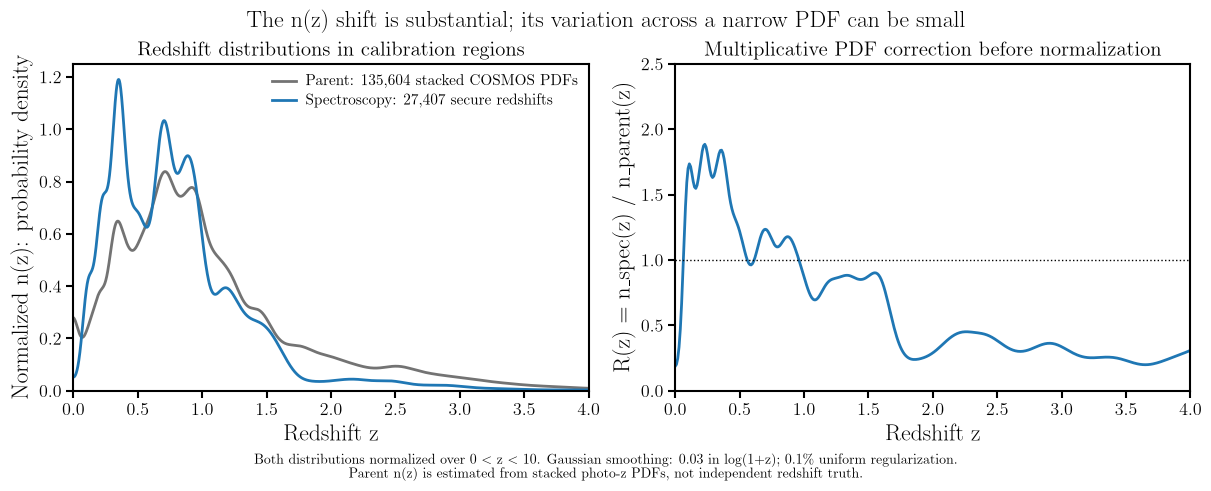

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'paper/data/predictions.npz').exists())
OUT=ROOT/'results/coverage_prior_correction'
with np.load(OUT/'diagnostics.npz') as f:d={k:f[k] for k in f.files}
with np.load(OUT/'all_models_diagnostics.npz') as f:a={k:f[k] for k in f.files}
with np.load(ROOT/'paper/data/predictions.npz') as f:q={k:f[k] for k in f.files}
np.testing.assert_array_equal(d['id'],q['id'])
grid=d['grid'];ratio=d['ratio_h_0.030'];zg=d['z_density']
names=['lephare_full_cosmos','cosmos_pdf_flow','eazy_rprior','eazy_six_band']
stats={}
for name in names:
    bounds=q[f'{name}_quantiles'][:,[1,3]]
    factors=[]
    for lo,hi in bounds:
        seg=ratio[(grid>lo)&(grid<hi)]
        vals=np.r_[np.interp([lo,hi],grid,ratio),seg]
        factors.append(vals.max()/vals.min())
    change=abs(a[f'{name}_pit_h_0.030']-a[f'{name}_pit_original'])
    stats[name]={
        'ratio_max_over_min_within_original_central68_p50_p90_p95':np.quantile(factors,[.5,.9,.95]).tolist(),
        'absolute_pit_change_p50_p90_p95':np.quantile(change,[.5,.9,.95]).tolist()}
(OUT/'prior_ratio_local_effect.json').write_text(json.dumps(stats,indent=2)+'\n')
print(json.dumps(stats,indent=2))
import sys
sys.path.insert(0,str(ROOT/'src'))
from pzflow.project_plot_style import set_style
set_style()
fig,axs=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
axs[0].plot(zg,d['parent_h_0.030']/(1+zg),color='0.45',lw=2,
            label='Parent: 135,604 stacked COSMOS PDFs')
axs[0].plot(zg,d['spec_h_0.030']/(1+zg),color='C0',lw=2,
            label='Spectroscopy: 27,407 secure redshifts')
axs[0].set(xlim=(0,4),ylim=(0,None),xlabel='Redshift z',
           ylabel='Normalized n(z): probability density',title='Redshift distributions in calibration regions')
axs[0].legend(fontsize=8.5)
axs[1].plot(grid,ratio,color='C0',lw=2)
axs[1].axhline(1,color='black',ls=':',lw=1)
axs[1].set(xlim=(0,4),ylim=(0,2.5),xlabel='Redshift z',
           ylabel='R(z) = n_spec(z) / n_parent(z)',title='Multiplicative PDF correction before normalization')
for ax in axs:ax.grid(alpha=.15)
fig.suptitle('The n(z) shift is substantial; its variation across a narrow PDF can be small',
             fontsize=13,fontweight='bold')
fig.supxlabel('Both distributions normalized over 0 < z < 10. Gaussian smoothing: 0.03 in log(1+z); 0.1% uniform regularization.\n'
              'Parent n(z) is estimated from stacked photo-z PDFs, not independent redshift truth.',fontsize=9)
fig.savefig(OUT/'redshift_distributions_and_ratio.png',dpi=180)
plt.show()
